In [7]:
# -------------------------------------------------------------
#   MARKETING CAMPAIGN — FULL PROJECT SOLUTION (Python Code)
# -------------------------------------------------------------

# ----------------- 1. IMPORT LIBRARIES ------------------------
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [13]:
sns.set(style="whitegrid")

# ----------------- LOAD THE DATA ------------------------------
data = pd.read_csv(r"C:\Users\Vaishali Rajput\Desktop\IITK\Class 6 Python project\1718968258_datasets\marketing_data.csv")

print("DATA HEAD:")
display(data.head())

print("\nDATA INFO:")
print(data.info())

print("\nMISSING VALUES:")
print(data.isnull().sum())

DATA HEAD:


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
0,1826,1970,Graduation,Divorced,"$84,835.00",0,0,6/16/14,0,189,...,6,1,0,0,0,0,0,1,0,SP
1,1,1961,Graduation,Single,"$57,091.00",0,0,6/15/14,0,464,...,7,5,0,0,0,0,1,1,0,CA
2,10476,1958,Graduation,Married,"$67,267.00",0,1,5/13/14,0,134,...,5,2,0,0,0,0,0,0,0,US
3,1386,1967,Graduation,Together,"$32,474.00",1,1,5/11/14,0,10,...,2,7,0,0,0,0,0,0,0,AUS
4,5371,1989,Graduation,Single,"$21,474.00",1,0,4/8/14,0,6,...,2,7,1,0,0,0,0,1,0,SP



DATA INFO:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   2240 non-null   int64 
 1   Year_Birth           2240 non-null   int64 
 2   Education            2240 non-null   object
 3   Marital_Status       2240 non-null   object
 4    Income              2216 non-null   object
 5   Kidhome              2240 non-null   int64 
 6   Teenhome             2240 non-null   int64 
 7   Dt_Customer          2240 non-null   object
 8   Recency              2240 non-null   int64 
 9   MntWines             2240 non-null   int64 
 10  MntFruits            2240 non-null   int64 
 11  MntMeatProducts      2240 non-null   int64 
 12  MntFishProducts      2240 non-null   int64 
 13  MntSweetProducts     2240 non-null   int64 
 14  MntGoldProds         2240 non-null   int64 
 15  NumDealsPurchases    2240 non-null   int64 

In [4]:
# --------------------------------------------------------------
# ----------------- 2. INVESTIGATE VARIABLES -------------------
# --------------------------------------------------------------

# CLEAN INCOME COLUMN
data["Income"] = (data["Income"].astype(str).str.replace("$", "").str.replace(",", ""))

# convert to float
data["Income"] = pd.to_numeric(data["Income"], errors="coerce")

# convert to datetime
data["Dt_Customer"] = pd.to_datetime(data["Dt_Customer"], errors="coerce")

print("\nIncome and Dt_Customer cleaned successfully.")
print(data[["Income", "Dt_Customer"]].head())

NameError: name 'data' is not defined

In [8]:
# --------------------------------------------------------------
# ----------- 3. MISSING VALUE IMPUTATION ----------------------
# --------------------------------------------------------------

print("\nMissing values before imputation:")
print(data.isnull().sum())

# Clean / combine categories
data["Education"] = data["Education"].str.lower().str.strip()
data["Marital_Status"] = data["Marital_Status"].str.lower().str.strip()

# Impute Income using mean Income grouped by Education & Marital_Status
group_income = data.groupby(["Education", "Marital_Status"])["Income"].mean()

def impute(row):
    if pd.isnull(row["Income"]):
        return group_income.loc[row["Education"], row["Marital_Status"]]
    return row["Income"]

data["Income"] = data.apply(impute, axis=1)

print("\nMissing values after Income imputation:")
print(data.isnull().sum())

# --------------------------------------------------------------
# ------------------ 4. CREATE NEW VARIABLES -------------------
# --------------------------------------------------------------

# AGE
data["Age"] = 2024 - data["Year_Birth"]

# SPENDING
spend_cols = ["MntWines","MntFruits","MntMeatProducts","MntFishProducts","MntSweetProducts","MntGoldProds"]
data["Spending"] = data[spend_cols].sum(axis=1)

# CHILDREN
data["Children_Count"] = data["Kidhome"] + data["Teenhome"]
data["Has_Children"] = (data["Children_Count"] > 0).astype(int)

# TOTAL PURCHASES
purchase_cols = ["NumDealsPurchases","NumWebPurchases","NumCatalogPurchases","NumStorePurchases"]
data["Total_Purchases"] = data[purchase_cols].sum(axis=1)

print("\nDerived columns created.")
data[["Age","Spending","Children_Count","Has_Children","Total_Purchases"]].head()

# --------------------------------------------------------------
# ----------- 5. HISTOGRAMS / BOXPLOTS + OUTLIERS --------------
# --------------------------------------------------------------

numeric_vars = ["Income","Spending","Age","Total_Purchases"]

for col in numeric_vars:
    plt.figure(figsize=(12,4))
    
    plt.subplot(1,2,1)
    sns.histplot(data[col], kde=True)
    plt.title("Histogram: " + col)

    plt.subplot(1,2,2)
    sns.boxplot(x=data[col])
    plt.title("Boxplot: " + col)

    plt.show()

    # OUTLIER CAPPING
    low = data[col].quantile(0.01)
    high = data[col].quantile(0.99)
    data[col] = np.clip(data[col], low, high)

print("\nOutlier treatment complete.")


Missing values before imputation:


NameError: name 'data' is not defined

NameError: name 'data' is not defined

In [18]:

# --------------------------------------------------------------
# -------------------- 6. ENCODING -----------------------------
# --------------------------------------------------------------

# EDUCATION — Ordinal encoding
edu_order = ["basic","high school","graduation","master","phd"]
data["Education_Ord"] = data["Education"].astype("category").cat.codes

# One-hot encode marital status & country
data = pd.get_dummies(data, columns=["Marital_Status","Country"], drop_first=True)

print("\nEncoding complete.")


Encoding complete.


In [19]:
# --------------------------------------------------------------
# ----------------- 7. CORRELATION ANALYSIS --------------------
# --------------------------------------------------------------

corr_vars = ["Income","Spending","Age","Total_Purchases","Children_Count","Has_Children"]
plt.figure(figsize=(10,6))
sns.heatmap(data[corr_vars].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()


KeyError: "['Income'] not in index"

<Figure size 1000x600 with 0 Axes>

In [3]:

# --------------------------------------------------------------
# ------------------ 8. HYPOTHESIS TESTING ---------------------
# --------------------------------------------------------------

print("\n----- HYPOTHESIS TESTS -----")

# H1: Income difference between customers WITH vs WITHOUT children
group_with = data[data["Has_Children"] == 1]["Income"]
group_without = data[data["Has_Children"] == 0]["Income"]

tstat1, pval1 = stats.ttest_ind(group_with, group_without)
print("\nH1: Income difference (children vs no children)")
print("t-statistic:", tstat1, "p-value:", pval1)

# H2: Age difference by campaign acceptance (AcceptedCmp5)
if "AcceptedCmp5" in data.columns:
    age_yes = data[data["AcceptedCmp5"] == 1]["Age"]
    age_no = data[data["AcceptedCmp5"] == 0]["Age"]

    tstat2, pval2 = stats.ttest_ind(age_yes, age_no)

    print("\nH2: Age difference by AcceptedCmp5")
    print("t-statistic:", tstat2, "p-value:", pval2)


----- HYPOTHESIS TESTS -----


NameError: name 'data' is not defined

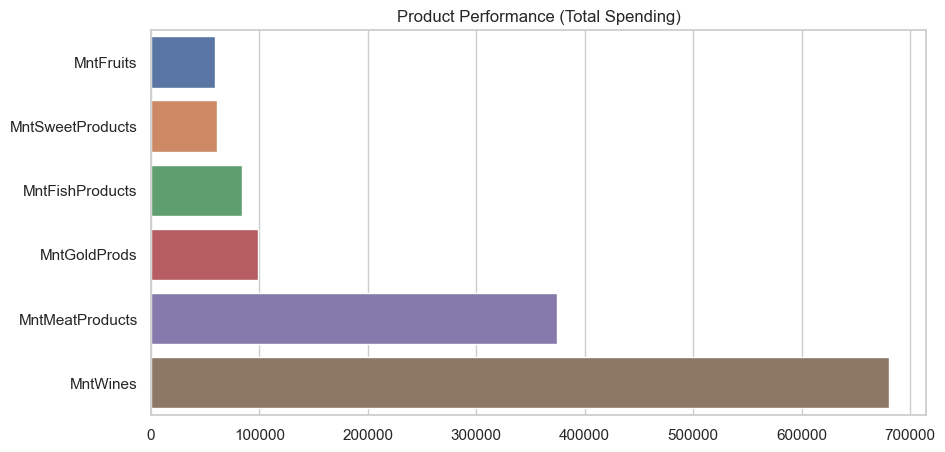

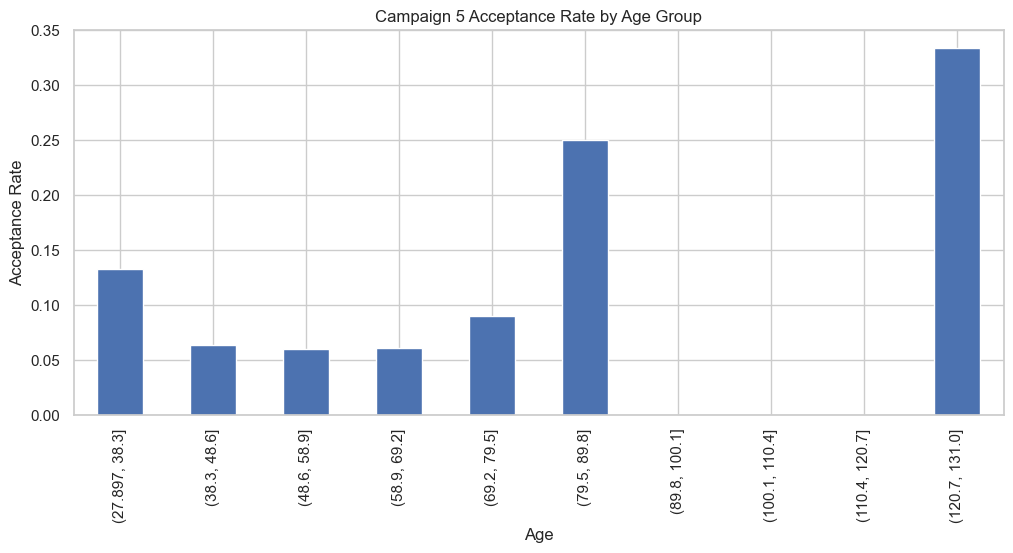

KeyError: 'Country'

In [22]:
# --------------------------------------------------------------
# ---------------------- 9. VISUALIZATIONS ---------------------
# --------------------------------------------------------------

# 1. Product performance
prod_perf = data[spend_cols].sum().sort_values()

plt.figure(figsize=(10,5))
sns.barplot(x=prod_perf.values, y=prod_perf.index)
plt.title("Product Performance (Total Spending)")
plt.show()

# 2. Age vs acceptance rate
if "AcceptedCmp5" in data.columns:
    age_bins = pd.cut(data["Age"], bins=10)
    age_accept = data.groupby(age_bins)["AcceptedCmp5"].mean()

    plt.figure(figsize=(12,5))
    age_accept.plot(kind="bar")
    plt.title("Campaign 5 Acceptance Rate by Age Group")
    plt.ylabel("Acceptance Rate")
    plt.show()

# 3. Country with most accepted campaign 5 customers
if "AcceptedCmp5" in data.columns:
    accepted_by_country = data[data["AcceptedCmp5"]==1]["Country"].value_counts()

    plt.figure(figsize=(8,4))
    sns.barplot(x=accepted_by_country.index, y=accepted_by_country.values)
    plt.title("Country With Most Accepted Campaign 5 Customers")
    plt.xticks(rotation=45)
    plt.show()

# 4. Children vs spending — strip plot
plt.figure(figsize=(8,5))
sns.stripplot(x=data["Children_Count"], y=data["Spending"])
plt.title("Children Count vs Spending")
plt.show()

# 5. Customers who complained — education
complained = data[data["Complain"]==1]["Education"].value_counts()

plt.figure(figsize=(8,4))
sns.barplot(x=complained.index, y=complained.values)
plt.title("Education of Customers Who Complained (Last 2 Years)")
plt.show()

# 6. Income vs Spending — scatter
plt.figure(figsize=(6,4))
sns.scatterplot(x=data["Income"], y=data["Spending"])
plt.title("Income vs Spending")
plt.show()

print("\nPROJECT COMPLETE ✔️")